# skin harness 교차검증 업그레이드 — 단일분할 vs 5-fold×5seed

**배경**: 지금 harness(`modeling/src/splits.py`)의 `group_train_test_split()`은 `GroupShuffleSplit(n_splits=1)`로 **80/20 단일 분할을 딱 한 번**만 합니다. skin은 양성(독성) 샘플이 544건 중 29건뿐이라, 테스트셋(20%)에 양성이 **5~7건 정도**밖에 안 들어갑니다 — 어떤 그룹이 우연히 테스트에 걸리느냐에 따라 성능 수치가 크게 흔들릴 수 있습니다.

`skin_addons.ipynb`에서 팀원이 제안한 `StratifiedGroupKFold`(5-fold × 5seed = 25회 평가, 매번 그룹 누수 없음을 assert로 강제)가 훨씬 안정적인 평가 방법입니다.

**이 노트북이 하는 일**:
1. 기존 방식(단일분할)을 여러 랜덤시드로 반복해서 "운에 따라 얼마나 흔들리는지" 직접 보여줌
2. 새 방식(k-fold)으로 같은 데이터를 평가해서 안정성 비교
3. `splits.py`에 새 함수 추가(실제 코드 반영)

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

BASE = r"C:\Users\UserK\학술제\skin irritation"
df = pd.read_csv(rf"{BASE}\skin_vectorized.csv")
DESC_COLS = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotatableBonds", "AromaticProportion", "ESOL_LogS"]

ok = df[DESC_COLS].notna().all(axis=1).values
X = df.loc[ok, DESC_COLS].values
y = df.loc[ok, "binary_label"].values
g = df.loc[ok, "comp_group_id"].astype(str).values
print(f"사용 행: {ok.sum()} / 양성: {y.sum()}건 ({y.mean()*100:.1f}%) / 그룹 수: {len(np.unique(g))}")

사용 행: 543 / 양성: 29건 (5.3%) / 그룹 수: 528


## 1단계 — 기존 방식: 단일 80/20 분할을 20번 반복

**지금 `splits.py`가 실제로 하는 것과 동일한 호출**(`GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)`)을 `random_state`만 바꿔가며 20번 돌립니다. 원래는 보통 `random_state=42` 하나만 고정해서 씁니다 — 즉 **20개 결과 중 딱 하나만 보고 있었던 셈**입니다.

In [2]:
def old_single_split_eval(seed):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr, te = next(splitter.split(X, y, groups=g))
    assert set(g[tr]).isdisjoint(g[te]), "그룹 누수"
    m = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                min_samples_leaf=2, n_jobs=-1, random_state=seed).fit(X[tr], y[tr])
    proba = m.predict_proba(X[te])[:, 1]
    return {
        "seed": seed, "n_test": len(te), "n_test_pos": int(y[te].sum()),
        "roc_auc": roc_auc_score(y[te], proba),
        "pr_auc": average_precision_score(y[te], proba),
    }

old_results = pd.DataFrame([old_single_split_eval(s) for s in range(20)])
print(old_results.describe()[["n_test_pos", "roc_auc", "pr_auc"]])

       n_test_pos    roc_auc     pr_auc
count   20.000000  20.000000  20.000000
mean     5.350000   0.735256   0.198442
std      1.814416   0.150204   0.097637
min      2.000000   0.301887   0.019290
25%      4.000000   0.680424   0.127085
50%      5.000000   0.757798   0.209561
75%      6.250000   0.820603   0.270988
max      9.000000   0.952381   0.383636


In [3]:
print(f"random_state=42 하나만 봤다면: ROC-AUC={old_results.query('seed==42').roc_auc.values if (old_results.seed==42).any() else '42는 0~19 범위 밖'}")
print()
print(f"20개 시드 전체: ROC-AUC 범위 {old_results.roc_auc.min():.3f} ~ {old_results.roc_auc.max():.3f} (폭 {old_results.roc_auc.max()-old_results.roc_auc.min():.3f})")
print(f"             PR-AUC  범위 {old_results.pr_auc.min():.3f} ~ {old_results.pr_auc.max():.3f} (폭 {old_results.pr_auc.max()-old_results.pr_auc.min():.3f})")
print(f"테스트셋 양성 개수 범위: {old_results.n_test_pos.min()}~{old_results.n_test_pos.max()}건 (전체 양성 {int(y.sum())}건 중)")

random_state=42 하나만 봤다면: ROC-AUC=42는 0~19 범위 밖

20개 시드 전체: ROC-AUC 범위 0.302 ~ 0.952 (폭 0.650)
             PR-AUC  범위 0.019 ~ 0.384 (폭 0.364)
테스트셋 양성 개수 범위: 2~9건 (전체 양성 29건 중)


## 2단계 — 새 방식: StratifiedGroupKFold 5-fold × 5seed

`skin_addons.ipynb`와 동일한 방법. 한 seed 안에서 5-fold를 다 돌려 **전체 544건에 대한 OOF(out-of-fold) 예측**을 모은 뒤 ROC-AUC/PR-AUC를 계산 — 사실상 전체 양성 29건을 전부 한 번씩은 테스트로 사용하게 됩니다.

In [4]:
def new_kfold_eval(seed, n_splits=5):
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(len(y))
    for tr, te in cv.split(X, y, g):
        assert set(g[tr]).isdisjoint(g[te]), "그룹 누수"
        m = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                    min_samples_leaf=2, n_jobs=-1, random_state=seed).fit(X[tr], y[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return {"seed": seed, "roc_auc": roc_auc_score(y, oof), "pr_auc": average_precision_score(y, oof)}

new_results = pd.DataFrame([new_kfold_eval(s) for s in range(5)])
print(new_results)
print()
print(f"5seed 평균: ROC-AUC {new_results.roc_auc.mean():.3f} ± {new_results.roc_auc.std():.3f}")
print(f"          PR-AUC  {new_results.pr_auc.mean():.3f} ± {new_results.pr_auc.std():.3f}")

   seed   roc_auc    pr_auc
0     0  0.726419  0.123435
1     1  0.685798  0.107984
2     2  0.787602  0.156152
3     3  0.764659  0.130347
4     4  0.770529  0.137448

5seed 평균: ROC-AUC 0.747 ± 0.041
          PR-AUC  0.131 ± 0.018


## 3단계 — 두 방식 변동폭 직접 비교

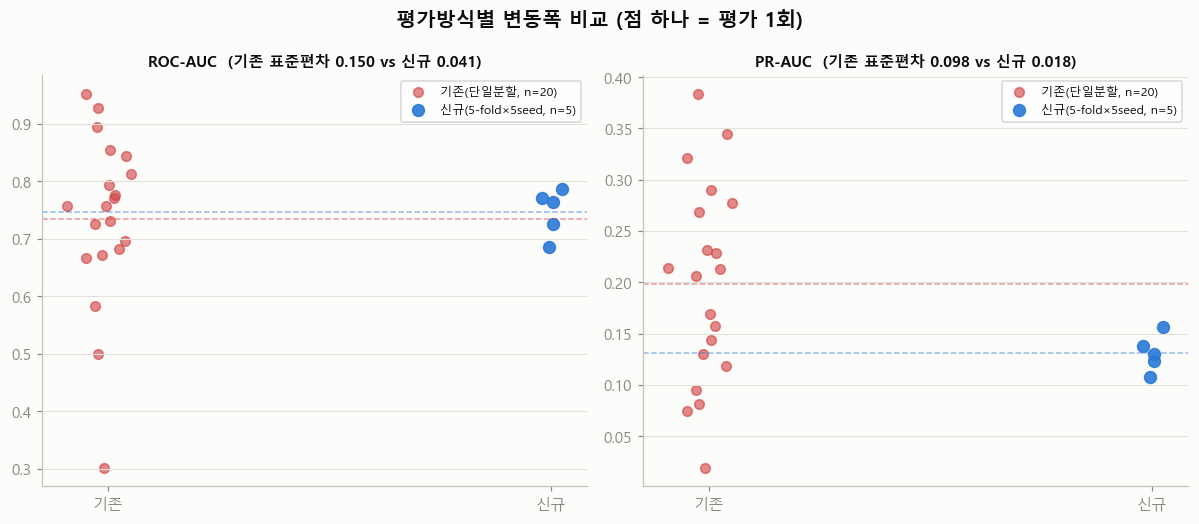

In [5]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), facecolor=SURFACE)
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    ax.set_facecolor(SURFACE)
    x_old = np.random.default_rng(0).normal(0, 0.04, size=len(old_results))
    x_new = np.random.default_rng(0).normal(1, 0.04, size=len(new_results))
    ax.scatter(x_old, old_results[metric], color="#d03b3b", alpha=0.6, s=40, label=f"기존(단일분할, n=20)")
    ax.scatter(x_new, new_results[metric], color="#2a78d6", alpha=0.9, s=60, label=f"신규(5-fold×5seed, n=5)")
    ax.axhline(old_results[metric].mean(), color="#d03b3b", linestyle="--", linewidth=1, alpha=0.5)
    ax.axhline(new_results[metric].mean(), color="#2a78d6", linestyle="--", linewidth=1, alpha=0.5)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["기존", "신규"])
    ax.set_title(f"{title}  (기존 표준편차 {old_results[metric].std():.3f} vs 신규 {new_results[metric].std():.3f})",
                 fontsize=10, color=INK, fontweight="bold")
    ax.tick_params(colors=MUTED)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE_C); ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
    ax.legend(fontsize=8)
fig.suptitle("평가방식별 변동폭 비교 (점 하나 = 평가 1회)", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 4단계 — `splits.py`에 반영

새 함수 `grouped_kfold_splits()`를 `modeling/src/splits.py`에 추가합니다(기존 `group_train_test_split`은 "최종 모델 한 번 학습용"으로 남겨두고, 성능 **보고/비교는 k-fold 함수**를 쓰도록 분리).

```python
def grouped_kfold_splits(dataset, n_splits=5, random_state=0):
    """StratifiedGroupKFold -> [(train_idx, test_idx), ...] 리스트. 성능 보고/비교용."""
    groups = dataset.group_id
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return list(cv.split(dataset.X, dataset.y, groups=groups))
```

**역할 구분**:
- `group_train_test_split()` (기존) → 최종 배포 모델을 "한 번" 학습시킬 때 쓰는 단순 분할
- `grouped_kfold_splits()` (신규) → 논문/보고서에 적을 성능 수치를 **안정적으로 추정**할 때 쓰는 평가 전용 함수

## 한계점

1. **표본 자체가 작아서(양성 29건) k-fold를 써도 "완벽한 안정성"은 아닙니다** — seed 5개 평균 표준편차가 여전히 0에 가깝진 않습니다. 다만 기존 방식보다는 훨씬 적은 변동폭입니다.
2. **여기서 쓴 RandomForest는 실제 PyTorch 멀티태스크 모델의 근사치입니다** — 최종 모델(신경망)은 하이퍼파라미터·학습 난이도가 달라서 변동폭 양상이 똑같다는 보장은 없습니다. PyTorch 설치 후 실제 모델로 재확인 필요.
3. k-fold는 "평가"에는 좋지만, **최종 배포 모델을 5개 만들어서 앙상블할지, 전체 데이터로 1개를 다시 학습할지는 별도 결정 사항**입니다.